# Alpha Alignment Notebook

## Purpose
This notebook aligns the tilt series (alpha axis) of ptychography XMCD and
charge contrast stacks. It takes the outputs of `Polarization_Alignment.ipynb`
and removes residual scan-to-scan lateral drift that varies systematically with
tilt angle.

Two complementary alignment strategies are used:

1. **Centroid-based alignment** — Track the fiducial hole cluster centroid
   across the tilt series. Fit a sinusoid to y (y shifts with projection)
   and a line to x (slow stage drift). Shift each scan to the fit curve.

2. **Cross-correlation alpha alignment** — Align consecutive tilt images
   (scan k -> scan k+1) by phase cross-correlation on the fiducial mask.
   CC, XMCD, and phase stacks are shifted by the same translation.

## Workflow
1. **Imports**
2. **User Configuration** — all tunable parameters in one place
3. **Load Data** — read CC, XMCD, OD stacks and angle arrays
4. **Single-Scan Preview** — verify fiducial detection on one scan
5. **Centroid Tracking** — compute fiducial centroid for every scan
6. **Fit Centroid Curves** — fit sinusoid (y) and line (x) to centroids
7. **Centroid-Based Alignment** — shift each scan to the fit target
8. **Verify Centroid Alignment** — re-track centroids and plot residuals
9. **Cross-Correlation Alpha Alignment** — align consecutive scans via CC
10. **Post-CC Centroid Check** — verify fiducial stability after CC alignment
11. **Save Outputs**

## Dependencies
All shared functions live in `Functions.py` (same directory) and are accessed
as `register.function_name()`.

---
## Step 1 — Imports

In [1]:
import numpy as np
import os
os.environ["OPENBLAS_NUM_THREADS"] = "1"
import tifffile
import matplotlib as mpl
import matplotlib.pyplot as plt

from scipy.fft import fftn, ifftn
from scipy.ndimage import fourier_shift
from scipy.optimize import curve_fit
import scipy.ndimage as ndimage

# All shared functions imported from Functions.py as 'register'
import Functions as register

---
## Step 2 — User Configuration

**Edit this cell for every new dataset / Gamma.**
All parameters that vary between samples, Gammas, or processing runs are
defined here and propagated automatically.

In [2]:
# --- Sample Identity ---------------------------------------------------------
sample   = "105"     
Gamma    = "Gamma45"  

# --- Data Directory ----------------------------------------------------------
data_dir =  f"/homes/emma/notebooks/RawData/{sample}/{Gamma}/"

# --- Plot Colors -------------------------------------------------------------
if sample == '452':
    fiduc_num = 3
    if Gamma == 'Gamma90':
        date  = '_16MAR26_og_ptycho'
        date1 = date           
        color_1 = 'darkmagenta'    
        color_2 = 'm'             
        
        color_list = ['m', 'darkmagenta', 'mediumvioletred', 'palevioletred']
    
    elif Gamma == 'Gamma0':
        date  = '_1APR26_recon_ptycho'
        date1 = date           
        color_1 = 'cornflowerblue'    
        color_2 = 'royalblue'              
        
        color_list = ['cornflowerblue', 'royalblue', 'tab:blue', 'blue']
    
    elif Gamma == 'Gamma45':
        date  = '_21MAR26_og_ptycho'
        date1 = date            # date1 used for angle files; set independently if different
        color_1 = 'limegreen'    # y-centroid + sin fit
        color_2 = 'darkgreen'              # x-centroid + linear fit
        
        color_list = ['limegreen', 'darkgreen', 'tab:green', 'green']

elif sample == '665':
    fiduc_num = 4
    if Gamma == 'Gamma0':
        date  = '_3AUG25_check_saturation_n50'
        date1 = date           
        color_1 = 'cornflowerblue'    
        color_2 = 'royalblue'              
        
        color_list = ['cornflowerblue', 'royalblue', 'tab:blue', 'blue']
    
    elif Gamma == 'Gammaneg45':
        date  = '_5AUG25_check_saturation_n50'
        date1 = date            # date1 used for angle files; set independently if different
        color_1 = 'limegreen'    # y-centroid + sin fit
        color_2 = 'darkgreen'              # x-centroid + linear fit
        
        color_list = ['limegreen', 'darkgreen', 'tab:green', 'green']


elif sample == '105':
    fiduc_num = 3
    if Gamma == 'Gamma0': 
        date = '_17NOV25_auto_select_scans_fullrange'
        date1 = date

        color_1 = 'cornflowerblue'          
        color_2 = 'royalblue' 
        color_list = ['cornflowerblue', 'royalblue', 'tab:blue', 'blue']

    elif Gamma == 'Gamma45':
        date = '_19NOV25_select_fullrange'
        date1 = date
        color_1 = 'limegreen'          
        color_2 = 'darkgreen' 
        color_list = ['limegreen', 'darkgreen', 'tab:green', 'green']


elif sample == '270':
    fiduc_num = 3
    if Gamma == "Gamma90":
        date  = '_29APR26_og_ptycho' #_Gamma0_bsub_kmenas'
        date1  = date  
        color_1 = 'm'          
        color_2 = 'darkmagenta' 
        color_list = ['m', 'darkmagenta', 'mediumvioletred', 'palevioletred']
    elif Gamma == "Gamma0": 
        # date  = '_16MAR26_og_ptycho'
        date  = '_29APR26_og_ptycho_light_on' #_Gamma0_bsub_kmenas_rot'
        date1 = date            
        color_1 = 'cornflowerblue'          
        color_2 = 'royalblue' 
        color_list = ['cornflowerblue', 'royalblue', 'tab:blue', 'blue']

        systematic_noise = True ## light was left on 
            
    elif Gamma == 'Gamma45': 
        date  = '_29APR26_og_ptycho' #_Gamma45_bsub_kmenas_rot'
        date1  = date    
        color_1 = 'limegreen'           # e.g. 'm', 'cornflowerblue', 'tab:blue'
        color_2 = 'darkgreen' # e.g. 'darkmagenta', 'royalblue'
        color_list = ['limegreen', 'darkgreen', 'tab:green', 'green']




# --- Alignment Parameters ----------------------------------------------------
# factor: pixels above (factor * image_max) treated as fiducial holes.
factor = 0.7

# bound: half-width of cross-correlation search window (pixels).
# Can also be specified per-scan in Step 9 via kbad list.
bound = 100

# Centroid y-axis display limits for fit plots (adjust to your image size).
centroid_ylim = (220, 320)

# --- Output Modifier ---------------------------------------------------------
modifier = 'bsub_kmeans_log10' #'bsub_kmeans_rot_log10' #'bsub_kmeans'#'bsub_kmenas' #'normalize_by_kmeans'  #'normalize_by_diffraction' #'all_scans_failed_psd'    # e.g. '_v2', '_centroid', '_xcorr'

# --- Summary -----------------------------------------------------------------
print(f"Configuration: Sample {sample}, {Gamma}")
print(f"  Data tag   : {date}")
print(f"  Data dir   : {data_dir}")
print(f"  Fiducials  : {fiduc_num}")
print(f"  factor={factor}, bound={bound}")

Configuration: Sample 105, Gamma45
  Data tag   : _19NOV25_select_fullrange
  Data dir   : /homes/emma/notebooks/RawData/105/Gamma45/
  Fiducials  : 3
  factor=0.7, bound=100


---
## Step 3 — Load Data

Reads the CC, XMCD, and OD stacks saved by `Polarization_Alignment.ipynb`,
along with the shifted angle array.

Expected filenames (matching Polarization_Alignment output convention):
- `OD_chrgcntrst_stack{date}.tiff` — charge contrast stack
- `OD_XMCD_stack{date}.tiff` — XMCD stack
- `OD_pospol_stack{date}.tiff` — positive polarization OD stack
- `OD_negpol_stack{date}.tiff` — negative polarization OD stack (aligned)
- `angles_shifted{date}.txt` — calibrated tilt angle array (zero = max contrast)

If your filenames differ, update the strings below.

In [3]:
# --- Build file paths --------------------------------------------------------
fn_CC     = f"OD_chrgcntrst_stack{date}_{Gamma}_{modifier}.tiff"
fn_XMCD   = f"OD_XMCD_stack{date}_{Gamma}_{modifier}.tiff" 
fn_ASYM   = f"OD_ASYM_stack{date}_{Gamma}_{modifier}.tiff"
fn_angles = f"angles_shifted{date1}_{Gamma}_{modifier}.txt"

# --- Load stacks -------------------------------------------------------------
image_CC   = tifffile.imread(os.path.join(data_dir, fn_CC))
image_XMCD = tifffile.imread(os.path.join(data_dir, fn_XMCD))
image_ASYM = tifffile.imread(os.path.join(data_dir, fn_ASYM))

##### mirror and invert neg45 #####
if sample =='665': 
    if Gamma == 'Gammaneg45': 
        image_CC =  image_CC[:, ::-1, :] 
        image_XMCD = image_XMCD[:, ::-1, :] *-1
        image_ASYM = image_ASYM[:, ::-1, :] *-1

# Phase stacks are optional; comment out if not available
# phase_CC = tifffile.imread(os.path.join(data_dir, f"phase_CC_stack{date}.tiff"))

angles = np.loadtxt(os.path.join(data_dir, fn_angles))

print(f"Loaded: {data_dir}")
print(f"  image_CC shape   : {image_CC.shape}")
print(f"  image_XMCD shape : {image_XMCD.shape}")
print(f"  image_ASYM shape : {image_ASYM.shape}")
print(f"  angles shape     : {angles.shape}")
print(f"  angle range      : [{angles[0]:.2f}, {angles[-1]:.2f}] deg")

Loaded: /homes/emma/notebooks/RawData/105/Gamma45/
  image_CC shape   : (38, 514, 514)
  image_XMCD shape : (38, 514, 514)
  image_ASYM shape : (38, 514, 514)
  angles shape     : (38,)
  angle range      : [-63.17, 63.17] deg


---
## Step 4 — Single-Scan Preview: Fiducial Detection

Verify that fiducial detection works correctly on one scan before tracking
the full stack. The CC image is inverted ((CC - 2) * -1) so that fiducial
holes appear as bright peaks.

Set `k` to any scan index to inspect.

Previewing k=5 | angle=-57.83 deg


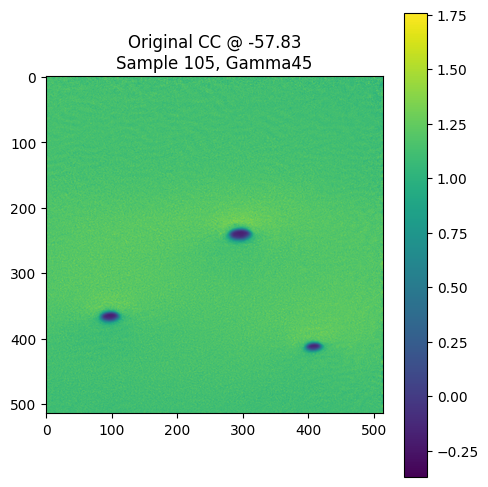

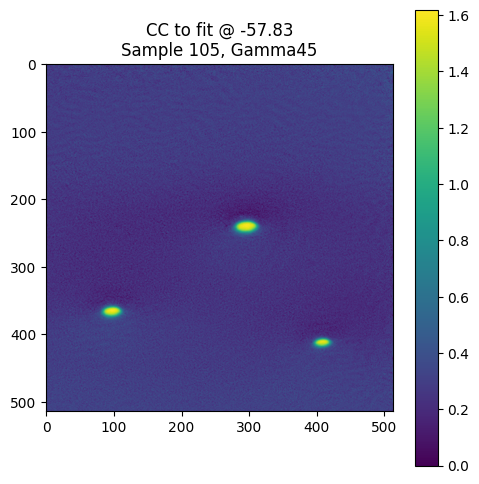

  Weighted centroid : y=254.91, x=256.58


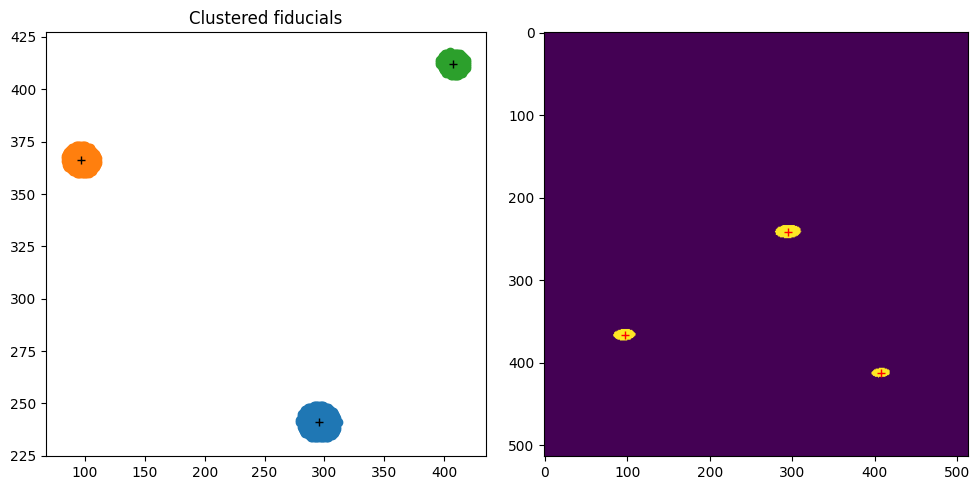

  KMeans centroid   : y=339.99, x=266.70


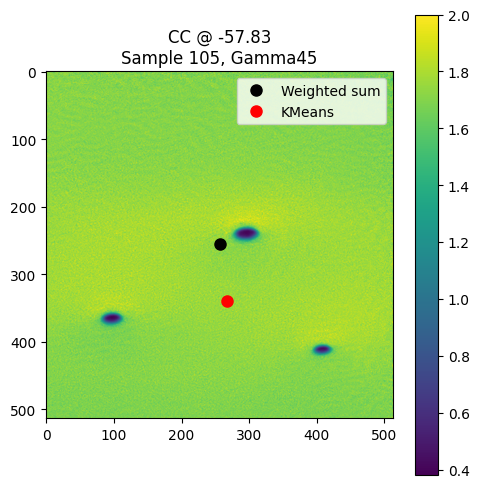

In [4]:
# --- Select scan to preview --------------------------------------------------
k = 5   # <-- change to inspect a different scan
# -----------------------------------------------------------------------------

angle = angles[k]
print(f"Previewing k={k} | angle={angle:.2f} deg")


# Plot image_CC
norm_CC = mpl.colors.Normalize(vmin=np.min(image_CC), vmax=np.max(image_CC))
fig, ax = plt.subplots(figsize=(5, 5))
img = ax.imshow(image_CC[k], cmap='viridis', norm=norm_CC)
ax.set_title(f"Original CC @ {angle:.2f}\nSample {sample}, {Gamma}")
fig.colorbar(img, ax=ax)
plt.tight_layout()
plt.show()

finite_CC = image_CC[k].astype(float)
finite_mask = np.isfinite(finite_CC)  # True for real numbers, False for nan/inf

# max over finite pixels only
mx = finite_CC[finite_mask].max() if np.any(finite_mask) else 0.0
CC_to_fit = np.full_like(finite_CC, np.nan)   # or 0.0 if you prefer
CC_to_fit[finite_mask] = mx - finite_CC[finite_mask]   

# Invert CC so holes appear bright for centroid fitting
# CC_to_fit = (finite_CC)*-1 + (np.max(finite_CC))
# hole_thresh = np.nanmax(CC_to_fit)
# print(hole_thresh)

# Plot CCtofit
norm_CC = mpl.colors.Normalize(vmin=np.nanmin(CC_to_fit), vmax=np.nanmax(CC_to_fit))
fig, ax = plt.subplots(figsize=(5, 5))
img = ax.imshow(CC_to_fit, cmap='viridis', norm=norm_CC)
ax.set_title(f"CC to fit @ {angle:.2f}\nSample {sample}, {Gamma}")
fig.colorbar(img, ax=ax)
plt.tight_layout()
plt.show()


# Method 1: intensity-weighted centroid of the whole image
y_weighted, x_weighted = register.calculate_centroid(CC_to_fit)
print(f"  Weighted centroid : y={y_weighted:.2f}, x={x_weighted:.2f}")

# Method 2: KMeans fiducial point centroid (preferred)
factor = 1.7
points   = register.find_fiducial_points(CC_to_fit, fiduc_num, factor, verbose=True)
tuple_set = set(tuple(row) for row in points)
y1, x1   = register.calculate_centroid_points(tuple_set)
print(f"  KMeans centroid   : y={y1:.2f}, x={x1:.2f}")

# Plot CC with both centroids marked
norm_CC = mpl.colors.Normalize(vmin=np.min(CC_to_fit * -1 + 2), vmax=np.max(CC_to_fit * -1 + 2))
fig, ax = plt.subplots(figsize=(5, 5))
img = ax.imshow(CC_to_fit * -1 + 2, cmap='viridis', norm=norm_CC)
ax.plot(x_weighted, y_weighted, 'ko', markersize=8, label='Weighted sum')
ax.plot(x1,         y1,         'ro', markersize=8, label='KMeans')
ax.set_title(f"CC @ {angle:.2f}\nSample {sample}, {Gamma}")
ax.legend()
fig.colorbar(img, ax=ax)
plt.tight_layout()
plt.show()

---
## Step 5 — Centroid Tracking (All Scans)

Compute the KMeans fiducial centroid for every scan in the stack.
These raw centroid trajectories are then fitted in Step 6.

In [5]:
y_centroid = []
x_centroid = []

for k in range(image_CC.shape[0]):
    # # CC_to_fit = np.nan_to_num((image_CC[k] - 2) * -1, nan=0.0)
    # CC_to_fit = np.nan_to_num((image_CC[k])*-1 + (np.max(image_CC[k])), nan = 0.0)

    finite_CC = image_CC[k].astype(float)
    finite_mask = np.isfinite(finite_CC)  # True for real numbers, False for nan/inf
    
    # max over finite pixels only
    mx = finite_CC[finite_mask].max() if np.any(finite_mask) else 0.0
    CC_to_fit = np.full_like(finite_CC, np.nan)   # or 0.0 if you prefer
    CC_to_fit[finite_mask] = mx - finite_CC[finite_mask]   

    # Cluster
    points    = register.find_fiducial_points(CC_to_fit, fiduc_num, factor, verbose=False)
    tuple_set = set(tuple(row) for row in points)
    y1, x1   = register.calculate_centroid_points(tuple_set)
    y_centroid.append(y1)
    x_centroid.append(x1)

y_centroid = np.array(y_centroid)
x_centroid = np.array(x_centroid)

print(f"Centroid tracking complete: {image_CC.shape[0]} scans")
print(f"  y range: [{np.nanmin(y_centroid):.2f}, {np.nanmax(y_centroid):.2f}]")
print(f"  x range: [{np.nanmin(x_centroid):.2f}, {np.nanmax(x_centroid):.2f}]")

Centroid tracking complete: 38 scans
  y range: [159.55, 414.12]
  x range: [189.79, 358.33]


---
## Step 6 — Fit Centroid Curves

- **y-centroid:** Fitted with a sinusoid (`register.sin_fit`) because the
  fiducial centroid sweeps vertically as the sample tilts in the beam.
- **x-centroid:** Fitted with a line (`register.lin_fit`) because x-drift
  is dominated by slow linear stage motion.

The mean x (`mean_x`) and the sinusoidal y fit (`y_sin_fit`) define the
**target centroid position** for each scan in Step 7.

y sin fit params : [ 42.55910828 283.37290795   3.44286945]
x lin fit params : [-18.48596163 265.71948667]
Mean centroid: y=289.41, x=270.85


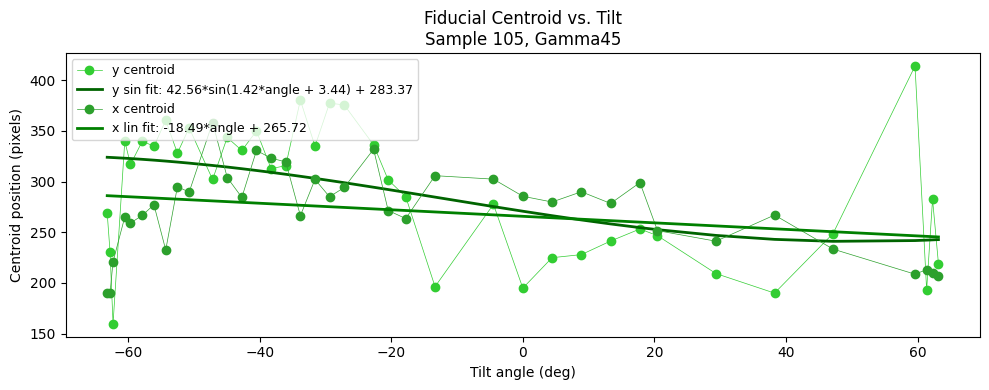

In [6]:
# --- Build angle arrays for fitting ------------------------------------------
# plot_angles     = np.linspace(angles[0], np.max(angles),
#                               angles.shape[0])
plot_angles     = angles
plot_angles_rad = np.deg2rad(plot_angles)

# --- Fit sinusoid to y-centroid -----------------------------------------------
bounds_sin = ([0, 0, -2 * np.pi], [np.inf, np.inf, 2 * np.pi])
guess_sin  = [10, np.mean(y_centroid), 6]

y_params, _ = curve_fit(register.sin_fit, plot_angles_rad, y_centroid,
                        p0=guess_sin, bounds=bounds_sin)
y_sin_fit = register.sin_fit(plot_angles_rad, *y_params)
b_fix = np.pi / np.ptp(plot_angles_rad)
y_fit_label = (f"y sin fit: {y_params[0]:.2f}*sin({b_fix:.2f}*angle "
               f"+ {y_params[2]:.2f}) + {y_params[1]:.2f}")
print(f"y sin fit params : {y_params}")

# --- Fit line to x-centroid --------------------------------------------------
x_params, _ = curve_fit(register.lin_fit, plot_angles_rad, x_centroid, p0=[2, 2])
x_lin_fit = register.lin_fit(plot_angles_rad, *x_params)
x_fit_label = f"x lin fit: {x_params[0]:.2f}*angle + {x_params[1]:.2f}"
print(f"x lin fit params : {x_params}")

# --- Reference statistics ----------------------------------------------------
mean_x = np.mean(x_centroid)
mean_y = np.mean(y_centroid)
print(f"Mean centroid: y={mean_y:.2f}, x={mean_x:.2f}")

# --- Plot centroid data + fits -----------------------------------------------
register.plot_centroid_fits(
    plot_angles,
    y_centroid, x_centroid,
    y_sin_fit,  x_lin_fit,
    y_fit_label, x_fit_label,
    sample=sample, Gamma=Gamma,
    color_list = color_list,
    ylim= None
)

---
## Step 7 — Centroid-Based Alignment

Shift each scan so its fiducial centroid lands on:
- **y:** `y_sin_fit[k]` (the fitted sinusoid)
- **x:** `mean_x` (the mean x position across the series)

CC and XMCD stacks are shifted by the same (dy, dx) per scan.

In [7]:
aligned_CC   = np.zeros_like(image_CC)
aligned_XMCD = np.zeros_like(image_XMCD)
aligned_ASYM = np.zeros_like(image_ASYM)

y_shifts_centroid = np.empty(image_CC.shape[0])
x_shifts_centroid = np.empty(image_CC.shape[0])

for k in range(image_CC.shape[0]):

    finite_CC = image_CC[k].astype(float)
    finite_mask = np.isfinite(finite_CC)  # True for real numbers, False for nan/inf
    
    # max over finite pixels only
    mx = finite_CC[finite_mask].max() if np.any(finite_mask) else 0.0
    CC_to_fit = np.full_like(finite_CC, np.nan)   # or 0.0 if you prefer
    CC_to_fit[finite_mask] = mx - finite_CC[finite_mask]  
    
    # CC_to_fit = (image_CC[k])*-1 + (np.max(image_CC[k]))
    # hole_thresh = np.nanmax(CC_to_fit)
    # # CC_to_fit = np.nan_to_num((image_CC[k] - 2) * -1, nan=0.0)
    # #CC_to_fit = np.nan_to_num((image_CC[k])*-1 + (np.max(image_CC[k])), nan = 0.0)
    points    = register.find_fiducial_points(CC_to_fit, fiduc_num, factor, verbose=False)
    tuple_set = set(tuple(row) for row in points)
    y1, x1   = register.calculate_centroid_points(tuple_set)

    y_shift = y_sin_fit[k] - y1   # shift y toward sinusoidal fit
    x_shift = mean_x       - x1   # shift x toward mean position

    y_shifts_centroid[k] = y_shift
    x_shifts_centroid[k] = x_shift

    aligned_CC[k]   = ndimage.shift(image_CC[k],   shift=(y_shift, x_shift),
                                    mode='constant', cval=np.nan, order=1)
    aligned_XMCD[k] = ndimage.shift(image_XMCD[k], shift=(y_shift, x_shift),
                                    mode='constant', cval=np.nan, order=1)
    aligned_ASYM[k] = ndimage.shift(image_ASYM[k], shift=(y_shift, x_shift),
                                    mode='constant', cval=np.nan, order=1)

print(f"Centroid alignment complete.")
print(f"  y shift range: [{y_shifts_centroid.min():.3f}, {y_shifts_centroid.max():.3f}] px")
print(f"  x shift range: [{x_shifts_centroid.min():.3f}, {x_shifts_centroid.max():.3f}] px")

Centroid alignment complete.
  y shift range: [-172.347, 164.177] px
  x shift range: [-87.486, 81.054] px


Previewing k=0 | angle=-63.17 deg


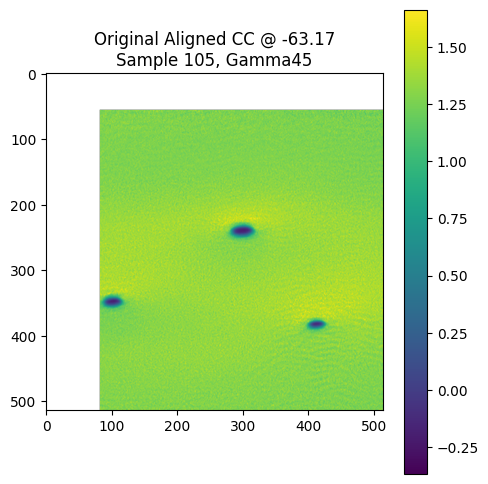

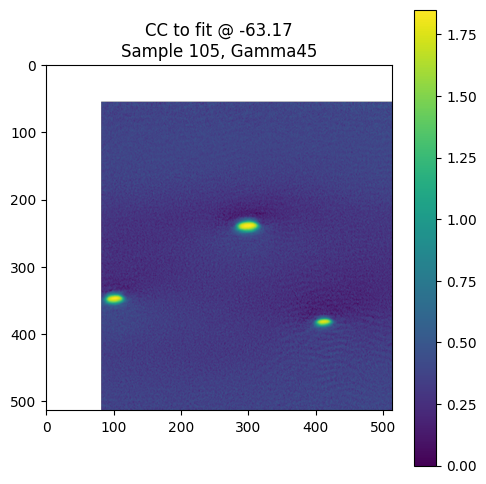

  Weighted centroid : y=nan, x=nan


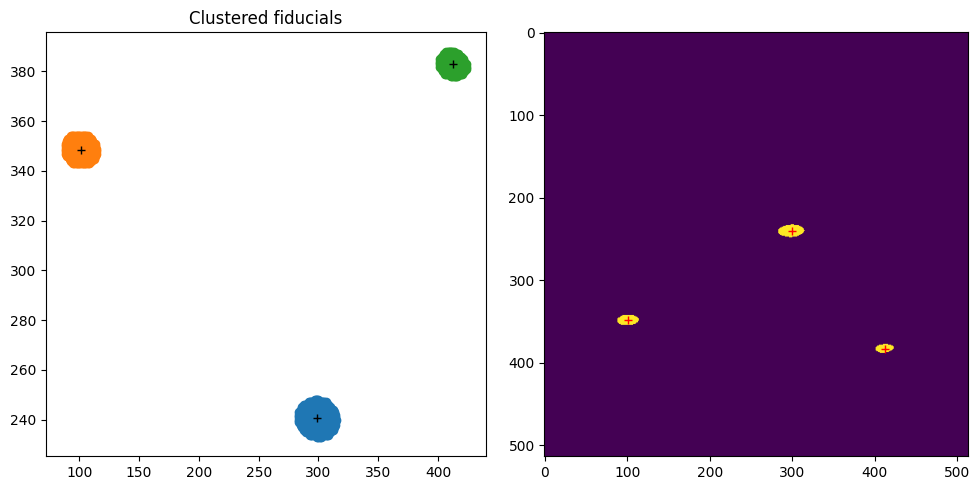

  KMeans centroid   : y=324.00, x=270.83


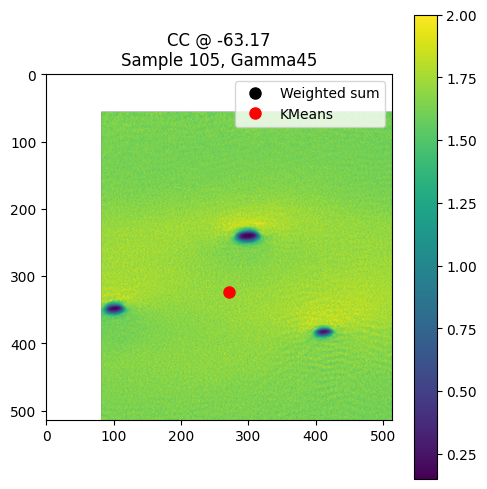

In [8]:
# --- Select scan to preview --------------------------------------------------
k = 0   # <-- change to inspect a different scan
# -----------------------------------------------------------------------------

angle = angles[k]
print(f"Previewing k={k} | angle={angle:.2f} deg")

# Plot aligned_CC
norm_CC = mpl.colors.Normalize(vmin=np.nanmin(aligned_CC), vmax=np.nanmax(aligned_CC))
fig, ax = plt.subplots(figsize=(5, 5))
img = ax.imshow(aligned_CC[k], cmap='viridis', norm=norm_CC)
ax.set_title(f"Original Aligned CC @ {angle:.2f}\nSample {sample}, {Gamma}")
fig.colorbar(img, ax=ax)
plt.tight_layout()
plt.show()


# Invert CC so holes appear bright for centroid fitting
# CC_to_fit = (aligned_CC[k])*-1 + (np.nanmax(aligned_CC[k]))
# print((np.nanmax(aligned_CC[k])))

# hole_thresh = np.nanmax(CC_to_fit)
# print(hole_thresh)

finite_CC = aligned_CC[k].astype(float)
finite_mask = np.isfinite(finite_CC)  # True for real numbers, False for nan/inf

# max over finite pixels only
mx = finite_CC[finite_mask].max() if np.any(finite_mask) else 0.0
CC_to_fit = np.full_like(finite_CC, np.nan)   # or 0.0 if you prefer
CC_to_fit[finite_mask] = mx - finite_CC[finite_mask]  


# Plot CCtofit
norm_CC = mpl.colors.Normalize(vmin=np.nanmin(CC_to_fit), vmax=np.nanmax(CC_to_fit))
fig, ax = plt.subplots(figsize=(5, 5))
img = ax.imshow(CC_to_fit, cmap='viridis', norm=norm_CC)
ax.set_title(f"CC to fit @ {angle:.2f}\nSample {sample}, {Gamma}")
fig.colorbar(img, ax=ax)
plt.tight_layout()
plt.show()


# Method 1: intensity-weighted centroid of the whole image
y_weighted, x_weighted = register.calculate_centroid(CC_to_fit)
print(f"  Weighted centroid : y={y_weighted:.2f}, x={x_weighted:.2f}")

# Method 2: KMeans fiducial point centroid (preferred)
factor = 1.7
points   = register.find_fiducial_points(CC_to_fit, fiduc_num, factor, verbose=True)
tuple_set = set(tuple(row) for row in points)
y1, x1   = register.calculate_centroid_points(tuple_set)
print(f"  KMeans centroid   : y={y1:.2f}, x={x1:.2f}")

# Plot CC with both centroids marked
norm_CC = mpl.colors.Normalize(vmin=np.nanmin(CC_to_fit * -1 + 2), vmax=np.nanmax(CC_to_fit * -1 + 2))
fig, ax = plt.subplots(figsize=(5, 5))
img = ax.imshow(CC_to_fit * -1 + 2, cmap='viridis', norm=norm_CC)
ax.plot(x_weighted, y_weighted, 'ko', markersize=8, label='Weighted sum')
ax.plot(x1,         y1,         'ro', markersize=8, label='KMeans')
ax.set_title(f"CC @ {angle:.2f}\nSample {sample}, {Gamma}")
ax.legend()
fig.colorbar(img, ax=ax)
plt.tight_layout()
plt.show()

---
## Step 8 — Verify Centroid Alignment

Re-track centroids in the aligned stack and plot against the fit targets.
If the alignment succeeded, the aligned y-centroid should follow the
sin fit and x-centroid should be flat near `mean_x`.

289.4946332733801
(38,)


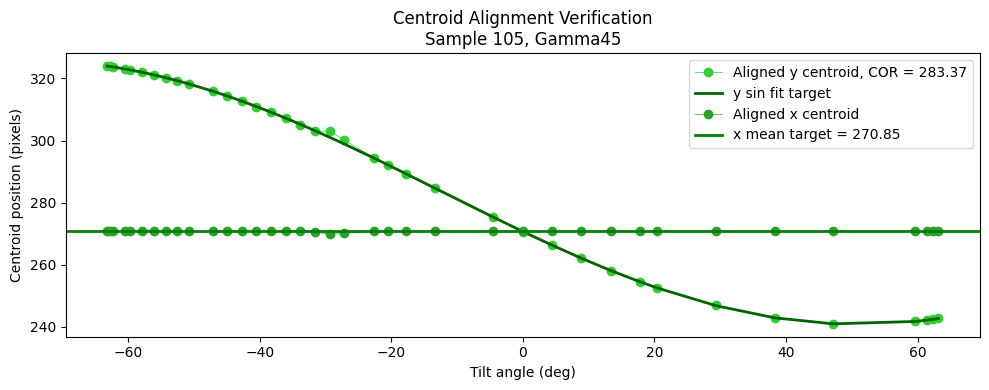

In [9]:
y_centroid_aligned = []
x_centroid_aligned = []

for k in range(aligned_CC.shape[0]):
    finite_CC = aligned_CC[k].astype(float)
    finite_mask = np.isfinite(finite_CC)  # True for real numbers, False for nan/inf
    
    # max over finite pixels only
    mx = finite_CC[finite_mask].max() if np.any(finite_mask) else 0.0
    CC_to_fit = np.full_like(finite_CC, np.nan)   # or 0.0 if you prefer
    CC_to_fit[finite_mask] = mx - finite_CC[finite_mask]  
    # #CC_to_fit = np.nan_to_num((aligned_CC[k] - 2) * -1, nan=0.0)
    # CC_to_fit = (aligned_CC[k])*-1 + (np.nanmax(aligned_CC[k]))
    # #CC_to_fit = np.nan_to_num((aligned_CC[k])*-1 + (np.max(aligned_CC[k])), nan = 0.0)
    
    points    = register.find_fiducial_points(CC_to_fit, fiduc_num, factor, verbose=False)
    tuple_set = set(tuple(row) for row in points)
    y1, x1   = register.calculate_centroid_points(tuple_set)
    y_centroid_aligned.append(y1)
    x_centroid_aligned.append(x1)

y_centroid_aligned = np.array(y_centroid_aligned)
x_centroid_aligned = np.array(x_centroid_aligned)

print(np.mean(y_centroid_aligned))
print(plot_angles.shape)
# Plot aligned centroids vs. fit targets
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(plot_angles, y_centroid_aligned, color=color_list[0], marker='o',
        linewidth=0.5, label=f'Aligned y centroid, COR = {y_params[1]:.2f}')
ax.plot(plot_angles, y_sin_fit,          color=color_list[1],
        linewidth=2,   label='y sin fit target')
ax.plot(plot_angles, x_centroid_aligned, color=color_list[2], marker='o',
        linewidth=0.5, label='Aligned x centroid')
ax.axhline(mean_x, color=color_list[3], linewidth=2,
           label=f'x mean target = {mean_x:.2f}')
ax.set_xlabel('Tilt angle (deg)')
ax.set_ylabel('Centroid position (pixels)')
ax.set_title(f"Centroid Alignment Verification\nSample {sample}, {Gamma}")
ax.legend()
# if centroid_ylim:
#     ax.set_ylim(centroid_ylim)
plt.tight_layout()
plt.show()

In [10]:
raise SystemExit("At this point, proceed to step 11 and save some scans. Proceed if the alignment still looks bad.")

SystemExit: At this point, proceed to step 11 and save some scans. Proceed if the alignment still looks bad.

/global/software/miniconda3/envs/pystxm/lib/python3.11/site-packages/IPython/core/interactiveshell.py:3709: UserWarning: To exit: use 'exit', 'quit', or Ctrl-D.
  warn("To exit: use 'exit', 'quit', or Ctrl-D.", stacklevel=1)


---
## Step 9 — Cross-Correlation Alpha Alignment

Align each scan to its neighbor via phase cross-correlation on the fiducial
hole mask. Scan k+1 is aligned to the already-shifted scan k (chain alignment).
CC, XMCD, and phase stacks are translated by the same shift.

**When to use:** After centroid alignment, residual high-frequency jitter
may remain. Cross-correlation catches sub-pixel shifts that the centroid
fit cannot resolve.

**`kbad`:** Scans where the default `bound` is too small (large jumps).
These get a wider search window `bound_wide`.

In [ ]:
# --- Scans needing a wider search window -------------------------------------
# Fill this in after reviewing the centroid verification plot above.
# Example from Gammapos45: kbad = [13, 16, 21, 29, 33, 35, 50, 59, 60, 61, 67]
kbad       = []    # <-- edit if needed
bound_wide = 100   # used for scans in kbad

# --- Initialize output arrays ------------------------------------------------
shift_alpha      = np.zeros_like(image_CC,   dtype=np.float32)
shift_alpha_XMCD = np.zeros_like(image_XMCD, dtype=np.float32)
# Uncomment if phase stacks are available:
# shift_alpha_phase = np.zeros_like(phase_CC, dtype=np.float32)

# --- Main alignment loop -----------------------------------------------------
for k in range(image_CC.shape[0] - 1):

    current_bound = bound_wide if k in kbad else bound
    angle  = angles[k]
    angle2 = angles[k + 1]

    if k == 0:
        # First scan: no shift applied; use as the reference
        shift_alpha[k]      = image_CC[k]
        shift_alpha_XMCD[k] = image_XMCD[k]
        # shift_alpha_phase[k] = phase_CC[k]

        ref_CC = image_CC[k]
    else:
        # Chain: compare to the already-shifted scan k
        ref_CC = shift_alpha[k]

    # Fiducial mask cross-correlation
    masked_ref, masked_next = register.mask_holes_to_one(
        ref_CC, image_CC[k + 1], factor
    )
    translation, corr = register.align_images_CC(masked_ref, masked_next,
                                                  current_bound)

    # Apply Fourier shift to CC, XMCD (and phase if available)
    shift_alpha[k + 1] = ifftn(
        fourier_shift(fftn(image_CC[k + 1]), translation)
    ).real
    shift_alpha_XMCD[k + 1] = ifftn(
        fourier_shift(fftn(image_XMCD[k + 1]), translation)
    ).real
    # shift_alpha_phase[k + 1] = ifftn(
    #     fourier_shift(fftn(phase_CC[k + 1]), translation)
    # ).real

    # # Plot reference vs. shifted, and cross-correlation surface
    # register.plot_CC_crosscorr(
    #     shift_alpha[k], image_CC[k + 1], corr,
    #     angle1=angle, angle2=angle2,
    #     sample=sample, Gamma=Gamma
    # )

    # # Before/after difference maps
    # norm_diff = mpl.colors.Normalize(vmin=-1, vmax=1)
    # fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.5))
    # axes[0].imshow(image_CC[k] - image_CC[k + 1], cmap='viridis', norm=norm_diff)
    # axes[0].set_title(f"Unshifted diff\n{angle:.2f} - {angle2:.2f} deg")
    # axes[1].imshow(shift_alpha[k] - shift_alpha[k + 1], cmap='viridis', norm=norm_diff)
    # axes[1].set_title(f"Shifted diff\n{angle:.2f} - {angle2:.2f} deg")
    # plt.tight_layout()
    # plt.show()

print("Cross-correlation alpha alignment complete.")

---
## Step 10 — Post-CC Centroid Check

Crop a central patch and re-track the fiducial centroid in the CC-aligned
stack to confirm scan-to-scan stability after chain cross-correlation.

In [ ]:
# --- Crop parameters ---------------------------------------------------------
crop_half = 130
height, width = image_CC.shape[1:]
cy_opts = np.array([60, 300, 475, 60,  height // 2, 475, 60,  300, 475])
cx_opts = np.array([60, 60,  60,  300, width  // 2, 200, 475, 475, 475])
crop_region = 4   # <-- index into cy_opts/cx_opts

cy = cy_opts[crop_region]
cx = cx_opts[crop_region]

# --- Crop the CC-aligned stack -----------------------------------------------
shift_alpha_cropped = shift_alpha[
    :,
    cy - crop_half : cy + crop_half,
    cx - crop_half : cx + crop_half
]
print(f"Cropped stack shape: {shift_alpha_cropped.shape}")

# --- Track centroid in cropped stack -----------------------------------------
# Set n to the number of scans to track (or image_CC.shape[0] for all)
n = 3   # <-- change to check more scans

y_centroid_post = []
x_centroid_post = []

for k in range(n):
    points    = register.find_fiducial_points(shift_alpha_cropped[k],
                                               fiduc_num, verbose=False)
    tuple_set = set(tuple(row) for row in points)
    y1, x1   = register.calculate_centroid_points(tuple_set)
    y_centroid_post.append(y1)
    x_centroid_post.append(x1)

# --- Plot centroid stability --------------------------------------------------
plt.figure(figsize=(10, 4))
plt.plot(range(n), y_centroid_post, marker='o', color=color_1, label='y centroid')
plt.plot(range(n), x_centroid_post, marker='o', color=color_2, label='x centroid')
plt.xlabel('Scan index')
plt.ylabel('Centroid position (pixels)')
plt.title(f"Post-CC Centroid Stability\nSample {sample}, {Gamma}")
plt.legend()
plt.tight_layout()
plt.show()

# --- Plot cropped CC with centroid for each checked scan ---------------------
color_cc = 'green'


for scan in range(n):
    _, range_min, range_max, _, _ = (None,) + register.auto_normalize_charge(
        image_CC[min(60, image_CC.shape[0] - 1)], color_cc
    )[:3] + (None,)
    # Simpler: use fixed display range
    norm_charge = mpl.colors.Normalize(vmin=range_min, vmax=range_max)

    fig, ax = plt.subplots(figsize=(5, 5))
    crop_plot = ax.imshow(shift_alpha_cropped[scan], cmap='viridis', norm=norm_charge)
    ax.plot(x_centroid_post[scan], y_centroid_post[scan], 'ro')
    ax.set_title(f"Cropped CC @ {angles[scan]:.2f}\n"
                 f"centroid ({x_centroid_post[scan]:.2f}, "
                 f"{y_centroid_post[scan]:.2f})")
    fig.colorbar(crop_plot, ax=ax)
    plt.tight_layout()
    plt.show()

---
## Step 11 — Save Outputs

Write aligned stacks and centroid arrays to disk.
Uncomment the block(s) matching your active alignment path.

In [ ]:
raise SystemExit("Review alignment output above before saving.")

In [11]:
print(f"Saving to: {data_dir}")
print(f"Tag: {date}, {Gamma}, modifier: '{modifier}'")

Saving to: /homes/emma/notebooks/RawData/105/Gamma45/
Tag: _19NOV25_select_fullrange, Gamma45, modifier: 'bsub_kmeans_log10'


In [12]:
def save_tiff_replace_nan(data: np.ndarray, data_dir, output_path: str):
    """
    Replace NaN values with 0 and save as TIFF.
    Does not modify the original array.
    """
    clean_data = np.where(np.isnan(data), 0, data)
    
    # tifffile.imwrite(output_path, clean_data)
    tifffile.imwrite(os.path.join(data_dir, output_path), clean_data)
    print(f"Saved to {output_path} — replaced {np.isnan(data).sum()} NaN(s) with 0")


In [13]:
# save_tiff_replace_nan(aligned_CC, data_dir, f"center_alpha_aligned_CC{date}_{Gamma}_{modifier}.tiff")

# # save_tiff_replace_nan(aligned_XMCD, data_dir, f"center_alpha_aligned_XMCD{date}_{Gamma}_{modifier}.tiff")

# save_tiff_replace_nan(aligned_XMCD, data_dir, f"center_alpha_aligned_ASYM{date}_{Gamma}_{modifier}.tiff")

    

In [14]:

# --- Centroid-based alignment outputs ----------------------------------------
tifffile.imwrite(
    os.path.join(data_dir, f"center_alpha_aligned_CC{date}_{Gamma}_{modifier}.tiff"),
    aligned_CC
)
tifffile.imwrite(
    os.path.join(data_dir, f"center_alpha_aligned_XMCD{date}_{Gamma}_{modifier}.tiff"),
    aligned_XMCD
)
tifffile.imwrite(
    os.path.join(data_dir, f"center_alpha_aligned_ASYM{date}_{Gamma}_{modifier}.tiff"),
    aligned_ASYM
)

#####
np.savetxt(
    os.path.join(data_dir, f"center_y_centroid{date}_{Gamma}_{modifier}.txt"),
    y_centroid
)
np.savetxt(
    os.path.join(data_dir, f"center_x_centroid{date}_{Gamma}_{modifier}.txt"),
    x_centroid
)

np.savetxt(
    os.path.join(data_dir, f"center_y_centroid_aligned{date}_{Gamma}_{modifier}.txt"),
    y_centroid_aligned
)
np.savetxt(
    os.path.join(data_dir, f"center_x_centroid_aligned{date}_{Gamma}_{modifier}.txt"),
    x_centroid_aligned
)

np.savetxt(
    os.path.join(data_dir, f"center_y_sin_fit{date}_{Gamma}_{modifier}.txt"),
    y_sin_fit
)
np.savetxt(
    os.path.join(data_dir, f"center_x_mean{date}_{Gamma}_{modifier}.txt"),
    np.array([mean_x])
)

# --- Cross-correlation alpha alignment outputs (uncomment if Step 9 was run) -
# tifffile.imwrite(
#     os.path.join(data_dir, f"alpha_aligned_CC{date}_{Gamma}{modifier}.tiff"),
#     shift_alpha
# )
# tifffile.imwrite(
#     os.path.join(data_dir, f"alpha_aligned_XMCD{date}_{Gamma}{modifier}.tiff"),
#     shift_alpha_XMCD
# )

print("Save complete.")

Save complete.
